# DiD / 2 groups

## Variables

| symbol | meaning | values |
|---|---|---|
| $y$ | outcome | continuous |
| $t$ | **treatment-group indicator**: unit belongs to the group that gets treated | $t=1$ treated group, $t=0$ control group |
| $p$ | **post-period indicator**: observation is after the treatment date | $p=1$ post, $p=0$ pre |
| $t\cdot p$ | interaction: *the treated group, after treatment*, i.e. the only cell actually exposed to treatment | $1$ only if $t=1$ and $p=1$ |

$$y = \beta_0 + \beta_1 t + \beta_2 p + \beta_3\, t\cdot p + \varepsilon$$

$$E(y \mid t, p) = \beta_0 + \beta_1 t + \beta_2 p + \beta_3\, t p$$

Only $t\cdot p$ switches on the treatment, so $\beta_3$ is the treatment effect (DiD estimand).

## Cell means and coefficients

**Control group, pre-period** (untreated, pre):

$$\boxed{\beta_0 = E(y \mid t=0, p=0)}$$

**Group difference** (treated vs. control, before treatment; baseline gap in levels):

$$E(y \mid t=1, p=0) = \beta_0 + \beta_1
\;\Rightarrow\; \boxed{\beta_1 = E(y \mid t=1, p=0) - E(y \mid t=0, p=0)}$$

**Time effect** (post vs. pre in the control group; common trend):

$$E(y \mid t=0, p=1) = \beta_0 + \beta_2
\;\Rightarrow\; \boxed{\beta_2 = E(y \mid t=0, p=1) - E(y \mid t=0, p=0)}$$

**Treated group, post-period:**

$$E(y \mid t=1, p=1) = \beta_0 + \beta_1 + \beta_2 + \beta_3$$

$$\begin{aligned}
\Rightarrow \beta_3 &= E(y \mid t=1, p=1) - E(y \mid t=0, p=0) \\
&\quad - \bigl(E(y \mid t=1, p=0) - E(y \mid t=0, p=0)\bigr) \\
&\quad - \bigl(E(y \mid t=0, p=1) - E(y \mid t=0, p=0)\bigr) \\
&= \underbrace{E(y \mid t=1, p=1) - E(y \mid t=1, p=0)}_{\text{change in treated}}
 - \underbrace{\bigl(E(y \mid t=0, p=1) - E(y \mid t=0, p=0)\bigr)}_{\text{change in control}}
\end{aligned}$$

| | $p=0$ (pre) | $p=1$ (post) | post − pre |
|---|---|---|---|
| $t=0$ control | $\beta_0$ | $\beta_0+\beta_2$ | $\beta_2$ |
| $t=1$ treated | $\beta_0+\beta_1$ | $\beta_0+\beta_1+\beta_2+\beta_3$ | $\beta_2+\beta_3$ |
| treated − control | $\beta_1$ | $\beta_1+\beta_3$ | $\beta_3$ |

## Assumptions about $\varepsilon$

1. **Zero conditional mean:** $E(\varepsilon \mid t, p) = 0$. This is what makes the conditional expectation above equal to the linear part, so the cell means identify the $\beta$'s. Substantively it is the **parallel trends** assumption: without treatment, the treated group's mean would have changed by the same amount $\beta_2$ as the control group's. If the error had a group-specific time shift, $E(\varepsilon\mid t=1,p=1)\neq 0$, it would be absorbed into $\hat\beta_3$.
2. **No anticipation / exogenous group assignment:** $\varepsilon$ is uncorrelated with the treatment status $t\cdot p$ (conditional on $t$ and $p$). Units do not change behaviour before treatment, and group membership is not driven by shocks that arrive together with the treatment.
3. **Independence across observations:** $\varepsilon_i$ independent of $\varepsilon_j$ (random sampling). With repeated observations of the same unit (panel), errors are correlated within unit, so use cluster-robust standard errors.
4. **Variance:** homoskedastic $\mathrm{Var}(\varepsilon\mid t,p)=\sigma^2$ is only needed for classical standard errors; otherwise use heteroskedasticity-robust (HC) ones. OLS is still unbiased either way.
5. **Normality** $\varepsilon \sim N(0,\sigma^2)$: only needed for exact small-sample $t$/$F$ inference; consistency and asymptotic inference do not need it.
6. **Stable composition:** the groups are made up of the same kind of units in both periods (no selective attrition), so that $\varepsilon$ is not correlated with $p$ through who is observed.

In the simulation below, $\varepsilon_i \overset{iid}{\sim} N(0,\sigma^2)$ independent of $(t,p)$, so all of these hold by construction.

## Simulation

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)

# true parameters
beta0, beta1, beta2, beta3 = 10.0, 2.0, 1.5, 3.0   # beta3 = true treatment effect
sigma = 2.0
n = 4000                                              # observations (repeated cross-sections)

t = rng.integers(0, 2, n)            # treatment-group indicator
p = rng.integers(0, 2, n)            # post-period indicator
eps = rng.normal(0, sigma, n)        # E(eps | t, p) = 0, iid, homoskedastic

y = beta0 + beta1*t + beta2*p + beta3*t*p + eps
df = pd.DataFrame({"y": y, "t": t, "p": p})
df.head()

,y,t,p
0,7.918798,0,0
1,13.506679,1,1
2,14.705188,1,0
3,14.844896,0,0
4,10.548502,0,1


### Cell means vs. the formulas

The four sample means should be close to $\beta_0$, $\beta_0+\beta_1$, $\beta_0+\beta_2$, $\beta_0+\beta_1+\beta_2+\beta_3$.

In [2]:
means = df.groupby(["t", "p"])["y"].mean().unstack("p")
means.columns = ["pre (p=0)", "post (p=1)"]
means.index = ["control (t=0)", "treated (t=1)"]
print(means.round(3))

did = (means.loc["treated (t=1)", "post (p=1)"] - means.loc["treated (t=1)", "pre (p=0)"]) \
    - (means.loc["control (t=0)", "post (p=1)"] - means.loc["control (t=0)", "pre (p=0)"])
print("\nDiD from cell means:", round(did, 3), "(true beta3 =", beta3, ")")

               pre (p=0)  post (p=1)
control (t=0)      9.966      11.540
treated (t=1)     11.997      16.491

DiD from cell means: 2.92 (true beta3 = 3.0 )


### OLS regression: $\hat\beta_3$ equals the DiD of cell means

In [3]:
m = smf.ols("y ~ t + p + t:p", data=df).fit(cov_type="HC1")   # robust SEs
print(m.summary().tables[1])
print("\ntrue:", dict(Intercept=beta0, t=beta1, p=beta2, **{"t:p": beta3}))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.9659      0.062    161.990      0.000       9.845      10.087
t              2.0311      0.088     23.071      0.000       1.859       2.204
p              1.5738      0.090     17.459      0.000       1.397       1.751
t:p            2.9204      0.127     22.996      0.000       2.671       3.169

true: {'Intercept': 10.0, 't': 2.0, 'p': 1.5, 't:p': 3.0}


### Monte Carlo: unbiasedness of $\hat\beta_3$ and what happens if parallel trends fails

Second scenario violates $E(\varepsilon\mid t,p)=0$: the treated group gets an extra post-period shock $\delta=1.5$ that has nothing to do with treatment, so $\hat\beta_3$ is biased by about $\delta$.

In [6]:
def simulate(n=4000, delta=0.0, seed=None):
    r = np.random.default_rng(seed)
    t = r.integers(0, 2, n); p = r.integers(0, 2, n)
    eps = r.normal(0, sigma, n) + delta*t*p      # delta != 0 -> E(eps | t=1,p=1) != 0
    y = beta0 + beta1*t + beta2*p + beta3*t*p + eps
    X = np.column_stack([np.ones(n), t, p, t*p])
    return np.linalg.lstsq(X, y, rcond=None)[0][3]

R = 1000
ok  = np.array([simulate(delta=0.0, seed=s) for s in range(R)])
bad = np.array([simulate(delta=1.5, seed=s) for s in range(R)])
print(f"parallel trends holds : mean beta3_hat = {ok.mean():.3f}, sd = {ok.std():.3f}")
print(f"parallel trends fails : mean beta3_hat = {bad.mean():.3f}, sd = {bad.std():.3f}  (true {beta3})")

parallel trends holds : mean beta3_hat = 2.997, sd = 0.122
parallel trends fails : mean beta3_hat = 4.497, sd = 0.122  (true 3.0)


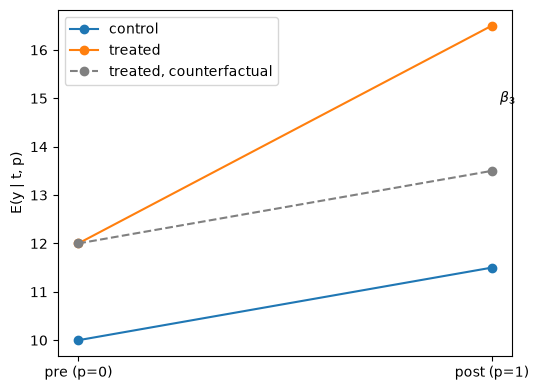

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5.5, 4))
x = [0, 1]
ctrl = [beta0, beta0 + beta2]
trt = [beta0 + beta1, beta0 + beta1 + beta2 + beta3]
cf = [beta0 + beta1, beta0 + beta1 + beta2]          # counterfactual: parallel trend
ax.plot(x, ctrl, "o-", label="control")
ax.plot(x, trt, "o-", label="treated")
ax.plot(x, cf, "o--", color="gray", label="treated, counterfactual")
ax.annotate(r"$\beta_3$", (1.02, (cf[1] + trt[1]) / 2), va="center")
ax.set_xticks(x); ax.set_xticklabels(["pre (p=0)", "post (p=1)"])
ax.set_ylabel("E(y | t, p)"); ax.legend(); plt.tight_layout()